In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

BASE = Path('/content/drive/MyDrive/ML Project_pneumonia/chest_xray')
IMG_EXT = {'.jpg', '.jpeg', '.png'}

def count_all(root):
    return sum(1 for f in root.rglob('*')
               if f.is_file() and f.suffix.lower() in IMG_EXT and not f.name.startswith('.'))

outer = sum(count_all(BASE / s) for s in ['train', 'val', 'test'])
inner = count_all(BASE / 'chest_xray')
print("Outer copy:", outer)
print("Inner copy:", inner)
print("Identical counts" if outer == inner else "Counts differ - tell me the numbers")

In [ ]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [14]:
from pathlib import Path

DATA_DIR = Path('/content/drive/MyDrive/ML Project_pneumonia/chest_xray')
IMG_EXT = {'.jpg', '.jpeg', '.png'}

EXPECTED = {
    ('train', 'NORMAL'): 1341, ('train', 'PNEUMONIA'): 3875,
    ('val',   'NORMAL'): 8,    ('val',   'PNEUMONIA'): 8,
    ('test',  'NORMAL'): 234,  ('test',  'PNEUMONIA'): 390,
}

grand_total = 0
print(f"{'split':<8}{'class':<12}{'found':>8}{'expected':>10}  status")
print("-" * 46)
for (split, cls), exp in EXPECTED.items():
    folder = DATA_DIR / split / cls
    if not folder.exists():
        print(f"{split:<8}{cls:<12}{'MISSING':>8}{exp:>10}  folder not found")
        continue
    n = sum(1 for f in folder.iterdir()
            if f.is_file() and f.suffix.lower() in IMG_EXT and not f.name.startswith('.'))
    grand_total += n
    print(f"{split:<8}{cls:<12}{n:>8}{exp:>10}  {'OK' if n == exp else 'CHECK'}")
print("-" * 46)
print(f"{'TOTAL':<20}{grand_total:>8}{5856:>10}")

split   class          found  expected  status
----------------------------------------------
train   NORMAL          1341      1341  OK
train   PNEUMONIA       3875      3875  OK
val     NORMAL             8         8  OK
val     PNEUMONIA          8         8  OK
test    NORMAL           234       234  OK
test    PNEUMONIA        390       390  OK
----------------------------------------------
TOTAL                   5856      5856


In [15]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
from pathlib import Path

SRC   = Path('/content/drive/MyDrive/ML Project_pneumonia/chest_xray')
LOCAL = Path('/content/data')

if not LOCAL.exists():
    LOCAL.mkdir()
    for split in ['train', 'val', 'test']:
        shutil.copytree(SRC / split, LOCAL / split)

print(sorted(os.listdir(LOCAL)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['test', 'train', 'val']


('train', 'NORMAL') 1341
('train', 'PNEUMONIA') 3875
('val', 'NORMAL') 8
('val', 'PNEUMONIA') 8
('test', 'NORMAL') 234
('test', 'PNEUMONIA') 390


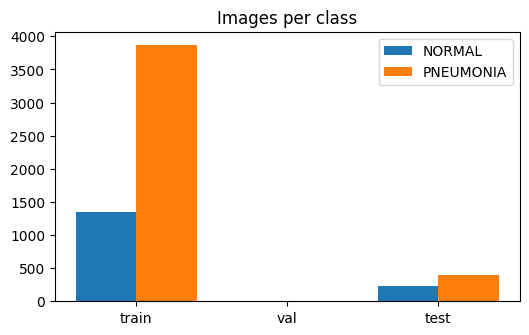

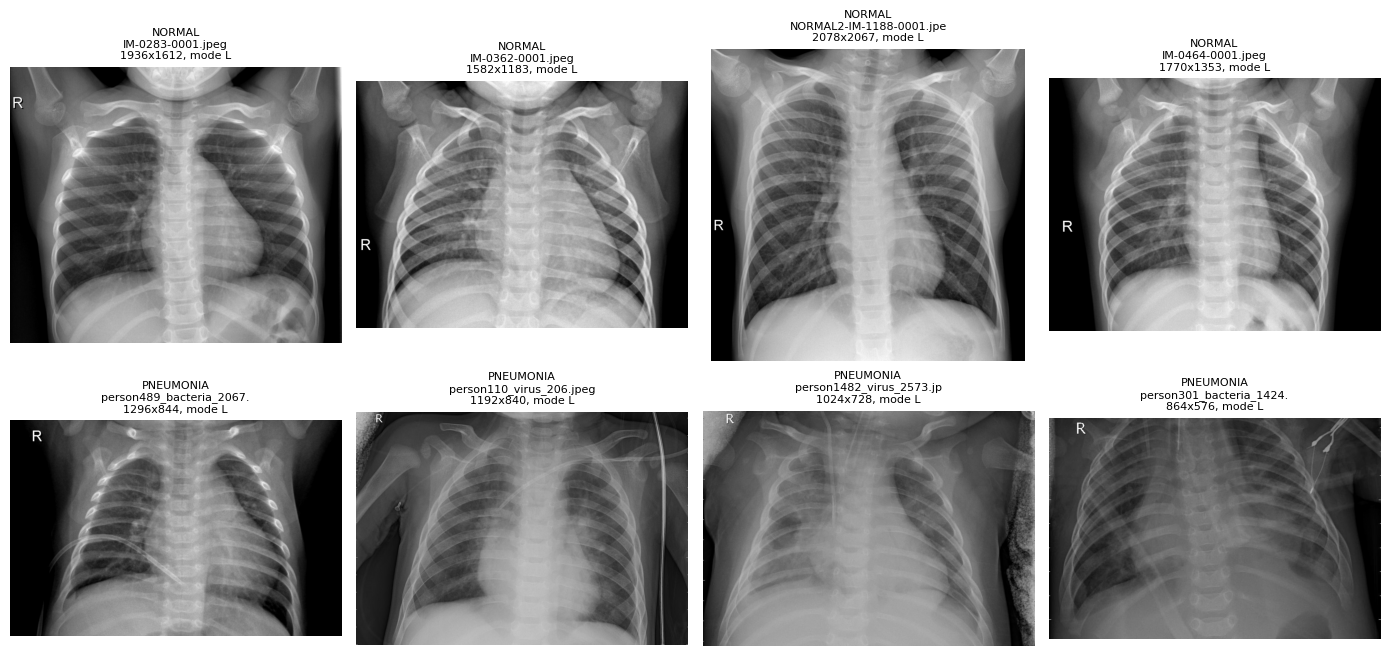

width  min / median / max: 445 1432 2721
height min / median / max: 187 1089 2578
color modes: Counter({'L': 293, 'RGB': 7})


In [16]:
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

IMG_EXT = {'.jpg', '.jpeg', '.png'}

def list_images(split, cls):
    return [f for f in (LOCAL / split / cls).iterdir()
            if f.suffix.lower() in IMG_EXT and not f.name.startswith('.')]

# 1) class balance
splits = ['train', 'val', 'test']
counts = {(s, c): len(list_images(s, c)) for s in splits for c in ['NORMAL', 'PNEUMONIA']}
for k, v in counts.items():
    print(k, v)

x = np.arange(len(splits))
plt.figure(figsize=(6, 3.5))
plt.bar(x - 0.2, [counts[(s, 'NORMAL')] for s in splits], width=0.4, label='NORMAL')
plt.bar(x + 0.2, [counts[(s, 'PNEUMONIA')] for s in splits], width=0.4, label='PNEUMONIA')
plt.xticks(x, splits); plt.legend(); plt.title('Images per class'); plt.show()

# 2) sample images
random.seed(0)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for r, cls in enumerate(['NORMAL', 'PNEUMONIA']):
    for c, f in enumerate(random.sample(list_images('train', cls), 4)):
        img = Image.open(f)
        axes[r][c].imshow(img, cmap='gray')
        axes[r][c].set_title(f"{cls}\n{f.name[:24]}\n{img.size[0]}x{img.size[1]}, mode {img.mode}", fontsize=8)
        axes[r][c].axis('off')
plt.tight_layout(); plt.show()

# 3) image sizes and color modes (sample of 300)
sample = random.sample(list_images('train', 'NORMAL'), 150) + random.sample(list_images('train', 'PNEUMONIA'), 150)
sizes, modes = [], []
for f in sample:
    with Image.open(f) as im:
        sizes.append(im.size); modes.append(im.mode)
w = np.array([s[0] for s in sizes]); h = np.array([s[1] for s in sizes])
print("width  min / median / max:", w.min(), int(np.median(w)), w.max())
print("height min / median / max:", h.min(), int(np.median(h)), h.max())
print("color modes:", Counter(modes))

In [17]:
import pandas as pd
rows = []
for cls in ['NORMAL', 'PNEUMONIA']:
    for f in random.sample(list_images('train', cls), 300):
        with Image.open(f) as im:
            rows.append((cls, im.size[0], im.size[1]))
df_sz = pd.DataFrame(rows, columns=['class', 'width', 'height'])
print(df_sz.groupby('class').median())

            width  height
class                    
NORMAL     1648.0  1316.0
PNEUMONIA  1144.0   752.0


In [18]:
import re
import pandas as pd

FIG_DIR = Path('/content/drive/MyDrive/ML Project_pneumonia/report_figures')
FIG_DIR.mkdir(exist_ok=True)

def save_show(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches='tight')
    plt.show()

def patient_id(name, cls):
    pat = r'(person\d+)' if cls == 'PNEUMONIA' else r'(IM-\d+)'
    m = re.search(pat, name)
    return f"{cls}_{m.group(1)}" if m else f"{cls}_{Path(name).stem}"

def collect(splits):
    rows = []
    for split in splits:
        for cls in ['NORMAL', 'PNEUMONIA']:
            for f in list_images(split, cls):
                rows.append((str(f), cls, int(cls == 'PNEUMONIA'), patient_id(f.name, cls)))
    return pd.DataFrame(rows, columns=['path', 'class', 'label', 'patient'])

pool    = collect(['train', 'val'])     # official val joins the pool
test_df = collect(['test'])             # stays untouched until the end

per_patient = pool.groupby('patient').size()
print("pool images:", len(pool), "| patients:", pool.patient.nunique())
print(pool.groupby('class').agg(images=('path', 'count'), patients=('patient', 'nunique')))
print("images per patient -> median:", per_patient.median(), "| max:", per_patient.max())

pool images: 5232 | patients: 2650
           images  patients
class                      
NORMAL       1349      1008
PNEUMONIA    3883      1642
images per patient -> median: 1.0 | max: 30


In [19]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

# Patient-aware split: ~80% train / ~20% validation
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(pool, pool.label, groups=pool.patient))
train_df, val_df = pool.iloc[tr_idx].copy(), pool.iloc[va_idx].copy()
assert set(train_df.patient).isdisjoint(set(val_df.patient)), "patient leakage!"

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f"{name:<6}{len(d):>6} images | pneumonia share {d.label.mean():.1%} | patients {d.patient.nunique()}")

# Demo: what a plain random split would do
rtr, rva = train_test_split(pool, test_size=0.2, stratify=pool.label, random_state=42)
leak = rva.patient.isin(set(rtr.patient)).mean()
print(f"\nRandom split: {leak:.0%} of validation images come from a patient who is also in training")
print("Patient split: 0%")

train   4182 images | pneumonia share 74.1% | patients 2120
val     1050 images | pneumonia share 74.8% | patients 530
test     624 images | pneumonia share 62.5% | patients 404

Random split: 68% of validation images come from a patient who is also in training
Patient split: 0%


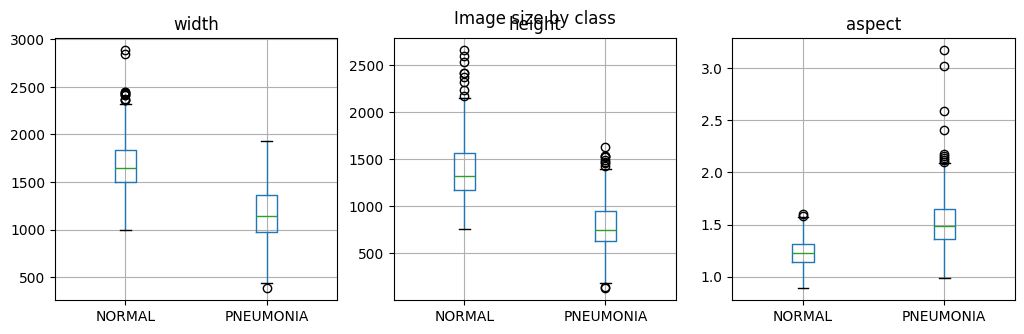

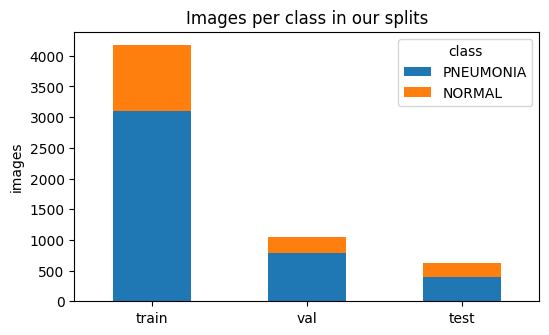

In [20]:
# Fig 3: image size by class (reuses df_sz from the size check)
df_sz['aspect'] = df_sz.width / df_sz.height
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, ['width', 'height', 'aspect']):
    df_sz.boxplot(column=col, by='class', ax=ax)
    ax.set_title(col); ax.set_xlabel('')
plt.suptitle('Image size by class')
save_show('fig3_image_size_by_class')

# Fig 4: class counts in our splits
split_tbl = pd.DataFrame({'train': train_df['class'].value_counts(),
                          'val':   val_df['class'].value_counts(),
                          'test':  test_df['class'].value_counts()}).T
split_tbl.plot(kind='bar', stacked=True, figsize=(6, 3.5), rot=0)
plt.title('Images per class in our splits'); plt.ylabel('images')
save_show('fig4_our_splits')

In [21]:
import tensorflow as tf

IMG, BATCH, AUTOTUNE = 224, 32, tf.data.AUTOTUNE

def load_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)   # force 3 channels
    img = tf.image.resize(img, (IMG, IMG))                               # fixed size
    return img, tf.cast(label, tf.float32)

def make_ds(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, df.label.values))
    if training:
        ds = ds.shuffle(len(df), seed=42)          # shuffle only for training
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

# sanity check on one batch
for imgs, labels in train_ds.take(1):
    print("batch:", imgs.shape, imgs.dtype, "| labels:", labels.shape,
          "| pixel range:", float(tf.reduce_min(imgs)), "-", float(tf.reduce_max(imgs)))

# class weights
n0, n1, n = (train_df.label == 0).sum(), (train_df.label == 1).sum(), len(train_df)
class_weight = {0: n / (2 * n0), 1: n / (2 * n1)}
print("class weights:", class_weight)

batch: (32, 224, 224, 3) <dtype: 'float32'> | labels: (32,) | pixel range: 0.0 - 255.0
class weights: {0: np.float64(1.9289667896678966), 1: np.float64(0.6749515816655907)}


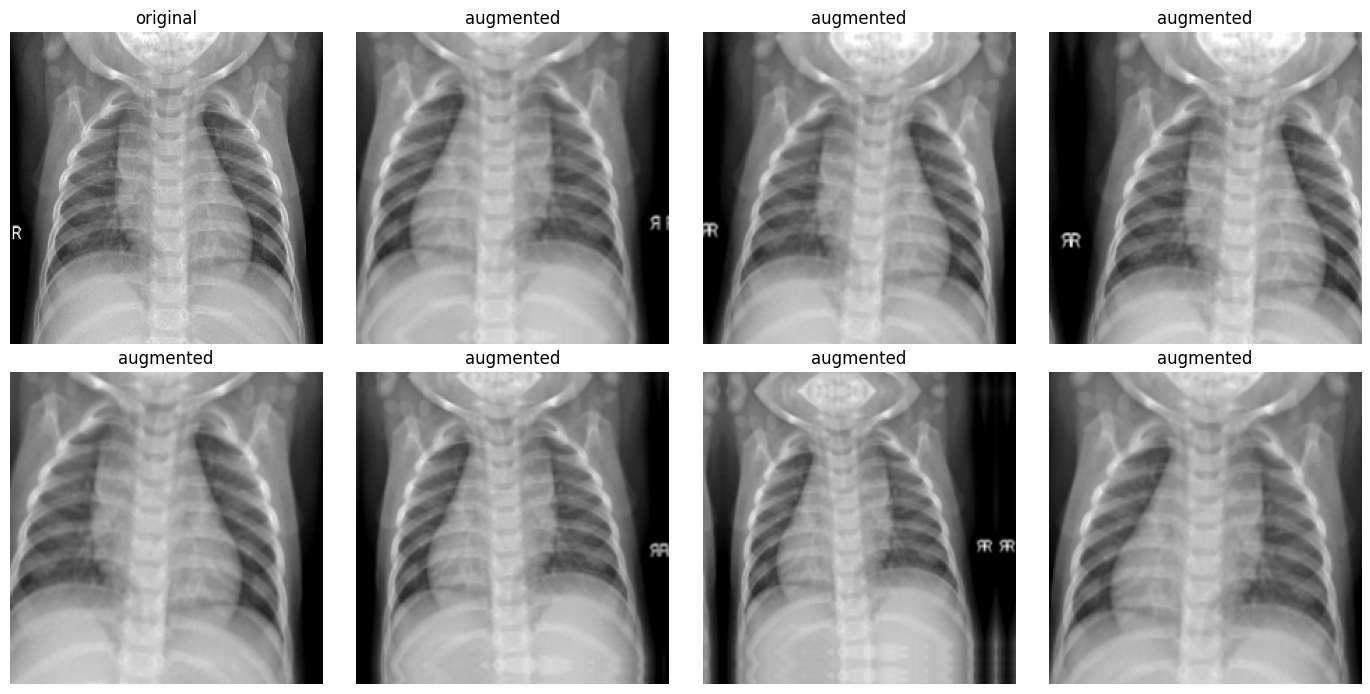

In [22]:
from tensorflow.keras import layers

augment = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.014),                                # about ±5°
    layers.RandomTranslation(height_factor=0.05, width_factor=0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
])

img, _ = load_image(train_df.path.iloc[0], 0)
show = lambda a: np.clip(a.numpy(), 0, 255).astype('uint8')

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0][0].imshow(show(img)); axes[0][0].set_title('original')
for ax in list(axes.flat)[1:]:
    ax.imshow(show(augment(tf.expand_dims(img, 0), training=True)[0]))
    ax.set_title('augmented')
for ax in axes.flat: ax.axis('off')
plt.tight_layout()
save_show('fig5_augmentation_examples')

In [23]:
from tensorflow.keras import layers, models

print("GPU available:", tf.config.list_physical_devices('GPU'))

augment = tf.keras.Sequential([
    layers.RandomRotation(0.014, fill_mode='constant', fill_value=0.0),   # about ±5°
    layers.RandomTranslation(0.05, 0.1, fill_mode='constant', fill_value=0.0),
    layers.RandomZoom(0.15, fill_mode='constant', fill_value=0.0),
    layers.RandomContrast(0.1),
], name='augment')

base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3),
                                         include_top=False, weights='imagenet')
base.trainable = False                       # freeze the pretrained part

inputs  = layers.Input(shape=(IMG, IMG, 3))
x = augment(inputs)                          # only active during training
x = layers.Rescaling(1/127.5, offset=-1)(x)  # scale 0-255 -> -1..1 (what MobileNetV2 expects)
x = base(x, training=False)                  # keeps BatchNorm layers in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
model = models.Model(inputs, outputs, name='pneumonia_mobilenetv2')

model.summary()

# sanity check: an untrained model should output values near 0.5
for imgs, labels in val_ds.take(1):
    print("untrained predictions:", model.predict(imgs[:4], verbose=0).ravel())

GPU available: []
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "pneumonia_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

untrained predictions: [0.72689015 0.5032177  0.50660384 0.64857894]


In [24]:
# ===== SETUP: run once after (re)starting the runtime =====
from google.colab import drive
drive.mount('/content/drive')

import os, re, shutil, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import StratifiedGroupKFold

print("GPU available:", tf.config.list_physical_devices('GPU'))

# 1) copy data from Drive to local disk
SRC   = Path('/content/drive/MyDrive/ML Project_pneumonia/chest_xray')
LOCAL = Path('/content/data')
if not LOCAL.exists():
    LOCAL.mkdir()
    for split in ['train', 'val', 'test']:
        shutil.copytree(SRC / split, LOCAL / split)

FIG_DIR = Path('/content/drive/MyDrive/ML Project_pneumonia/report_figures')
FIG_DIR.mkdir(exist_ok=True)
def save_show(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches='tight')
    plt.show()

# 2) patient-aware split
IMG_EXT = {'.jpg', '.jpeg', '.png'}
def list_images(split, cls):
    return [f for f in (LOCAL / split / cls).iterdir()
            if f.suffix.lower() in IMG_EXT and not f.name.startswith('.')]

def patient_id(name, cls):
    pat = r'(person\d+)' if cls == 'PNEUMONIA' else r'(IM-\d+)'
    m = re.search(pat, name)
    return f"{cls}_{m.group(1)}" if m else f"{cls}_{Path(name).stem}"

def collect(splits):
    rows = []
    for split in splits:
        for cls in ['NORMAL', 'PNEUMONIA']:
            for f in list_images(split, cls):
                rows.append((str(f), cls, int(cls == 'PNEUMONIA'), patient_id(f.name, cls)))
    return pd.DataFrame(rows, columns=['path', 'class', 'label', 'patient'])

pool, test_df = collect(['train', 'val']), collect(['test'])
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(pool, pool.label, groups=pool.patient))
train_df, val_df = pool.iloc[tr_idx].copy(), pool.iloc[va_idx].copy()
assert set(train_df.patient).isdisjoint(set(val_df.patient)), "patient leakage!"
for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f"{name:<6}{len(d):>6} images | pneumonia share {d.label.mean():.1%}")

# 3) data pipeline + class weights
IMG, BATCH, AUTOTUNE = 224, 32, tf.data.AUTOTUNE
def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, (IMG, IMG)), tf.cast(label, tf.float32)

def make_ds(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, df.label.values))
    if training:
        ds = ds.shuffle(len(df), seed=42)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)
n0, n1, n = (train_df.label == 0).sum(), (train_df.label == 1).sum(), len(train_df)
class_weight = {0: float(n / (2 * n0)), 1: float(n / (2 * n1))}
print("class weights:", class_weight)

# 4) model
augment = tf.keras.Sequential([
    layers.RandomRotation(0.014, fill_mode='constant', fill_value=0.0),
    layers.RandomTranslation(0.05, 0.1, fill_mode='constant', fill_value=0.0),
    layers.RandomZoom(0.15, fill_mode='constant', fill_value=0.0),
    layers.RandomContrast(0.1),
], name='augment')

base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights='imagenet')
base.trainable = False
inputs  = layers.Input(shape=(IMG, IMG, 3))
x = augment(inputs)
x = layers.Rescaling(1/127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
model = models.Model(inputs, outputs, name='pneumonia_mobilenetv2')
print("Trainable params:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU available: []
train   4182 images | pneumonia share 74.1%
val     1050 images | pneumonia share 74.8%
test     624 images | pneumonia share 62.5%
class weights: {0: 1.9289667896678966, 1: 0.6749515816655907}
Trainable params: 1281


In [25]:
import time

feat_model = models.Sequential([
    layers.Input((IMG, IMG, 3)),
    layers.Rescaling(1/127.5, offset=-1),
    base,                                    # frozen MobileNetV2
    layers.GlobalAveragePooling2D(),
], name='feature_extractor')

def extract(df, name):
    t = time.time()
    feats = feat_model.predict(make_ds(df), verbose=1)   # make_ds without shuffle keeps df order
    print(f"{name}: {feats.shape} in {(time.time() - t) / 60:.1f} min")
    return feats

X_val   = extract(val_df, 'val')       # smallest first, so we learn the speed early
X_test  = extract(test_df, 'test')
X_train = extract(train_df, 'train')
y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values

np.savez_compressed('/content/drive/MyDrive/ML Project_pneumonia/features_mobilenetv2.npz',
                    X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test)
print("saved features to Drive")

33/33 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step
val: (1050, 1280) in 1.0 min
20/20 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step
test: (624, 1280) in 0.7 min
131/131 ━━━━━━━━━━━━━━━━━━━━ 211s 2s/step
train: (4182, 1280) in 4.4 min
saved features to Drive


In [26]:
CKPT_DIR = Path('/content/drive/MyDrive/ML Project_pneumonia')
tf.keras.utils.set_random_seed(42)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')])

callbacks = [
    tf.keras.callbacks.BackupAndRestore(str(CKPT_DIR / 'backup_stage1')),
    tf.keras.callbacks.ModelCheckpoint(str(CKPT_DIR / 'stage1_best.keras'),
                                       monitor='val_auc', mode='max', save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
                                     patience=3, restore_best_weights=True),
    tf.keras.callbacks.CSVLogger(str(CKPT_DIR / 'stage1_log.csv'), append=True),
]

history1 = model.fit(train_ds, validation_data=val_ds, epochs=8,
                     class_weight=class_weight, callbacks=callbacks, verbose=1)

Epoch 1/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 354s 3s/step - accuracy: 0.8331 - auc: 0.9206 - loss: 0.3687 - precision: 0.9360 - recall: 0.8315 - val_accuracy: 0.8905 - val_auc: 0.9745 - val_loss: 0.2516 - val_precision: 0.9799 - val_recall: 0.8713
Epoch 2/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 312s 2s/step - accuracy: 0.9125 - auc: 0.9743 - loss: 0.2171 - precision: 0.9746 - recall: 0.9054 - val_accuracy: 0.9038 - val_auc: 0.9786 - val_loss: 0.2181 - val_precision: 0.9831 - val_recall: 0.8866
Epoch 3/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 304s 2s/step - accuracy: 0.9180 - auc: 0.9778 - loss: 0.1960 - precision: 0.9761 - recall: 0.9116 - val_accuracy: 0.9200 - val_auc: 0.9789 - val_loss: 0.1928 - val_precision: 0.9821 - val_recall: 0.9096
Epoch 4/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 315s 2s/step - accuracy: 0.9323 - auc: 0.9834 - loss: 0.1690 - precision: 0.9776 - recall: 0.9300 - val_accuracy: 0.9152 - val_auc: 0.9819 - val_loss: 0.1961 - val_precision: 0.9847 - val_recall: 0.9006
Epoch 5/8
131/131 ━━━━━━━━━━━━━━

best epoch 8: val acc 0.915 | AUC 0.984 | precision 0.989 | recall 0.897


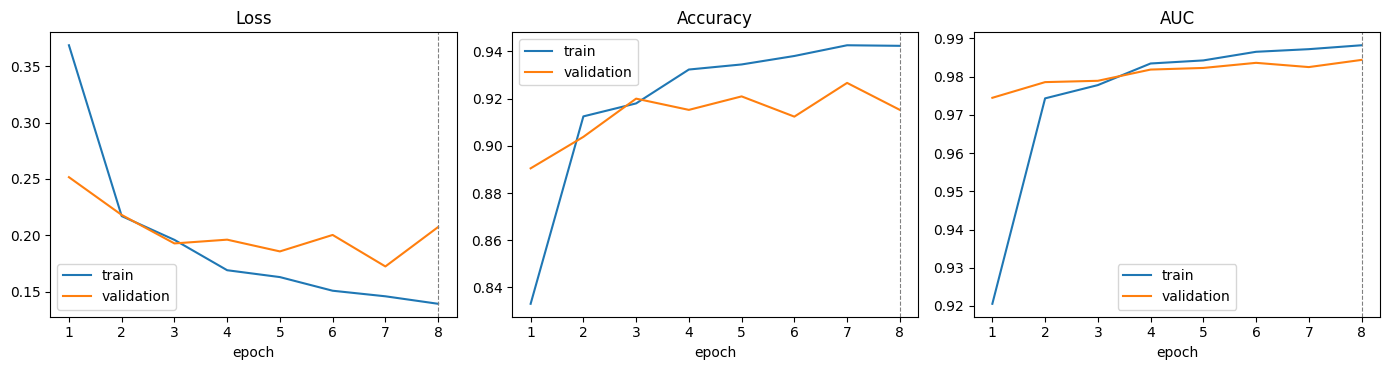

In [27]:
h = history1.history
best = int(np.argmax(h['val_auc']))
print(f"best epoch {best + 1}: val acc {h['val_accuracy'][best]:.3f} | AUC {h['val_auc'][best]:.3f} "
      f"| precision {h['val_precision'][best]:.3f} | recall {h['val_recall'][best]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (k, title) in zip(axes, [('loss', 'Loss'), ('accuracy', 'Accuracy'), ('auc', 'AUC')]):
    ax.plot(range(1, len(h[k]) + 1), h[k], label='train')
    ax.plot(range(1, len(h[k]) + 1), h['val_' + k], label='validation')
    ax.axvline(best + 1, ls='--', c='gray', lw=0.8)
    ax.set_title(title); ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout()
save_show('fig6_stage1_curves')

In [28]:
# unfreeze only the top ~30 layers of the base; keep BatchNorm layers frozen
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),          # 100x smaller learning rate
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')])
print("trainable params now:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

callbacks2 = [
    tf.keras.callbacks.BackupAndRestore(str(CKPT_DIR / 'backup_stage2')),
    tf.keras.callbacks.ModelCheckpoint(str(CKPT_DIR / 'stage2_best.keras'),
                                       monitor='val_auc', mode='max', save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max',
                                     patience=2, restore_best_weights=True),
    tf.keras.callbacks.CSVLogger(str(CKPT_DIR / 'stage2_log.csv'), append=True),
]

history2 = model.fit(train_ds, validation_data=val_ds, epochs=6,
                     class_weight=class_weight, callbacks=callbacks2, verbose=1)

trainable params now: 1512001
Epoch 1/6
131/131 ━━━━━━━━━━━━━━━━━━━━ 377s 3s/step - accuracy: 0.9486 - auc: 0.9882 - loss: 0.1326 - precision: 0.9855 - recall: 0.9445 - val_accuracy: 0.9390 - val_auc: 0.9831 - val_loss: 0.1695 - val_precision: 0.9865 - val_recall: 0.9312
Epoch 2/6
131/131 ━━━━━━━━━━━━━━━━━━━━ 381s 3s/step - accuracy: 0.9534 - auc: 0.9914 - loss: 0.1134 - precision: 0.9863 - recall: 0.9503 - val_accuracy: 0.9057 - val_auc: 0.9838 - val_loss: 0.2575 - val_precision: 0.9914 - val_recall: 0.8815
Epoch 3/6
131/131 ━━━━━━━━━━━━━━━━━━━━ 384s 3s/step - accuracy: 0.9560 - auc: 0.9920 - loss: 0.1107 - precision: 0.9857 - recall: 0.9545 - val_accuracy: 0.9038 - val_auc: 0.9860 - val_loss: 0.2728 - val_precision: 0.9942 - val_recall: 0.8764
Epoch 4/6
131/131 ━━━━━━━━━━━━━━━━━━━━ 383s 3s/step - accuracy: 0.9577 - auc: 0.9935 - loss: 0.0988 - precision: 0.9890 - recall: 0.9535 - val_accuracy: 0.9343 - val_auc: 0.9864 - val_loss: 0.1883 - val_precision: 0.9904 - val_recall: 0.9210
Ep

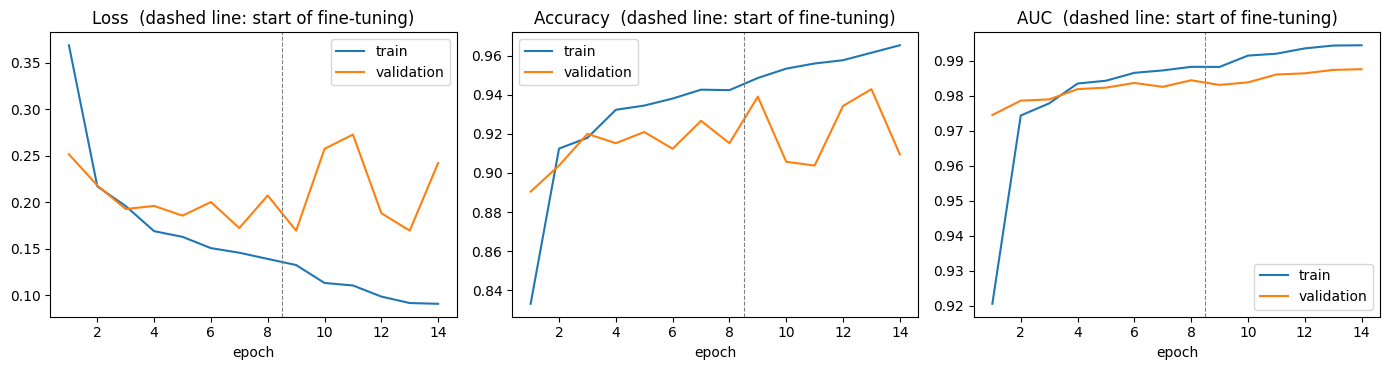

stage 2 best epoch 6: val acc 0.910 | AUC 0.988 | precision 0.994 | recall 0.884


In [29]:
h1, h2 = history1.history, history2.history
n1 = len(h1['loss'])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (k, title) in zip(axes, [('loss', 'Loss'), ('accuracy', 'Accuracy'), ('auc', 'AUC')]):
    tr, va = h1[k] + h2[k], h1['val_' + k] + h2['val_' + k]
    ep = range(1, len(tr) + 1)
    ax.plot(ep, tr, label='train'); ax.plot(ep, va, label='validation')
    ax.axvline(n1 + 0.5, ls='--', c='gray', lw=0.8)
    ax.set_title(title + '  (dashed line: start of fine-tuning)'); ax.set_xlabel('epoch'); ax.legend()
plt.tight_layout()
save_show('fig7_training_curves_both_stages')

best2 = int(np.argmax(h2['val_auc']))
print(f"stage 2 best epoch {best2 + 1}: val acc {h2['val_accuracy'][best2]:.3f} | AUC {h2['val_auc'][best2]:.3f} "
      f"| precision {h2['val_precision'][best2]:.3f} | recall {h2['val_recall'][best2]:.3f}")

In [30]:
import json
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve, f1_score,
                             ConfusionMatrixDisplay)

p_val  = model.predict(val_ds,  verbose=1).ravel()
p_test = model.predict(test_ds, verbose=1).ravel()
y_val, y_test = val_df.label.values, test_df.label.values

# thresholds chosen on VALIDATION only
fpr, tpr, thr = roc_curve(y_val, p_val)
t_youden   = float(thr[np.argmax(tpr - fpr)])          # official: balances recall and specificity
t_recall95 = float(thr[np.where(tpr >= 0.95)[0][0]])   # "screening mode": at least 95% recall on validation

def report(y, p, t, name):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {'set': name, 'threshold': round(t, 3), 'accuracy': (tp + tn) / len(y),
            'precision': tp / (tp + fp), 'recall': tp / (tp + fn),
            'specificity': tn / (tn + fp), 'f1': f1_score(y, pred),
            'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn}

rows = []
for tname, t in [('0.5', 0.5), ('Youden', t_youden), ('recall>=95%', t_recall95)]:
    rows.append(report(y_val,  p_val,  t, f'val  @ {tname}'))
    rows.append(report(y_test, p_test, t, f'test @ {tname}'))
results = pd.DataFrame(rows).set_index('set')
print(results.round(3).to_string())

auc_val, auc_test = roc_auc_score(y_val, p_val), roc_auc_score(y_test, p_test)
print(f"\nROC-AUC  validation: {auc_val:.4f} | test: {auc_test:.4f}")

# save for the report and for the Streamlit app
results.round(4).to_csv(CKPT_DIR / 'results_table.csv')
model.save(CKPT_DIR / 'final_model.keras')
json.dump({'threshold': t_youden}, open(CKPT_DIR / 'threshold.json', 'w'))
np.savez(CKPT_DIR / 'predictions.npz', p_val=p_val, y_val=y_val, p_test=p_test, y_test=y_test)

33/33 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step
                    threshold  accuracy  precision  recall  specificity     f1   TP  FP   TN  FN
set                                                                                             
val  @ 0.5              0.500     0.910      0.994   0.884        0.985  0.936  694   4  261  91
test @ 0.5              0.500     0.925      0.923   0.959        0.868  0.941  374  31  203  16
val  @ Youden           0.089     0.963      0.987   0.963        0.962  0.975  756  10  255  29
test @ Youden           0.089     0.885      0.847   0.995        0.701  0.915  388  70  164   2
val  @ recall>=95%      0.132     0.958      0.989   0.954        0.970  0.971  749   8  257  36
test @ recall>=95%      0.132     0.893      0.861   0.987        0.735  0.920  385  62  172   5

ROC-AUC  validation: 0.9905 | test: 0.9761


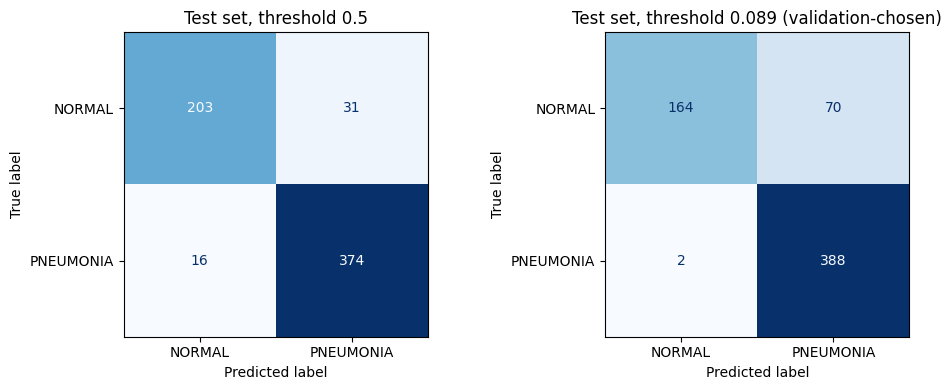

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (t, title) in zip(axes, [(0.5, 'threshold 0.5'), (t_youden, f'threshold {t_youden:.3f} (validation-chosen)')]):
    cm = confusion_matrix(y_test, (p_test >= t).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['NORMAL', 'PNEUMONIA']).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(f'Test set, {title}')
plt.tight_layout()
save_show('fig8b_confusion_matrices_two_thresholds')

training Logistic Regression ...
training SVM (RBF) ...
training Random Forest ...
                      model  set  accuracy  precision  recall  specificity   AUC
        Logistic Regression  val     0.973      0.988   0.976        0.966 0.997
        Logistic Regression test     0.808      0.770   0.987        0.509 0.944
                  SVM (RBF)  val     0.966      0.976   0.978        0.928 0.995
                  SVM (RBF) test     0.817      0.777   0.992        0.526 0.958
              Random Forest  val     0.952      0.955   0.982        0.864 0.988
              Random Forest test     0.763      0.727   0.995        0.376 0.966
MobileNetV2 fine-tuned (DL)  val     0.910      0.994   0.884        0.985 0.990
MobileNetV2 fine-tuned (DL) test     0.925      0.923   0.959        0.868 0.976


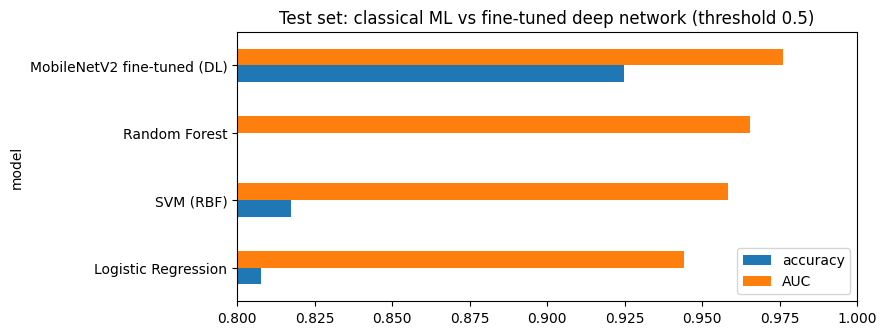

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

d = np.load(CKPT_DIR / 'features_mobilenetv2.npz')
Xtr, ytr, Xva, yva, Xte, yte = [d[k] for k in ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']]

ml_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'SVM (RBF)':           make_pipeline(StandardScaler(), SVC(C=1.0, class_weight='balanced', probability=True, random_state=42)),
    'Random Forest':       RandomForestClassifier(n_estimators=300, class_weight='balanced', n_jobs=-1, random_state=42),
}

def metrics(name, split, y, p, t=0.5):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {'model': name, 'set': split, 'accuracy': (tp + tn) / len(y), 'precision': tp / (tp + fp),
            'recall': tp / (tp + fn), 'specificity': tn / (tn + fp), 'AUC': roc_auc_score(y, p)}

rows = []
for name, m in ml_models.items():
    print("training", name, "...")
    m.fit(Xtr, ytr)
    rows.append(metrics(name, 'val',  yva, m.predict_proba(Xva)[:, 1]))
    rows.append(metrics(name, 'test', yte, m.predict_proba(Xte)[:, 1]))

rows.append(metrics('MobileNetV2 fine-tuned (DL)', 'val',  y_val,  p_val))
rows.append(metrics('MobileNetV2 fine-tuned (DL)', 'test', y_test, p_test))

cmp = pd.DataFrame(rows)
print(cmp.round(3).to_string(index=False))
cmp.round(4).to_csv(CKPT_DIR / 'model_comparison.csv', index=False)

# Fig 10: test-set comparison
t = cmp[cmp.set == 'test'].set_index('model')[['accuracy', 'AUC']]
t.plot(kind='barh', figsize=(8, 3.5)); plt.xlim(0.8, 1.0)
plt.title('Test set: classical ML vs fine-tuned deep network (threshold 0.5)')
save_show('fig10_model_comparison')

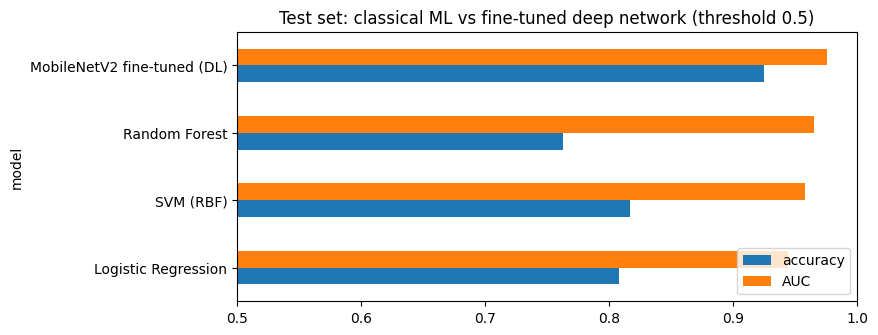

In [33]:
t = cmp[cmp.set == 'test'].set_index('model')[['accuracy', 'AUC']]
t.plot(kind='barh', figsize=(8, 3.5)); plt.xlim(0.5, 1.0)
plt.title('Test set: classical ML vs fine-tuned deep network (threshold 0.5)')
save_show('fig10_model_comparison')

In [34]:
from PIL import Image
from sklearn.ensemble import GradientBoostingClassifier

def size_features(df):
    out = []
    for p in df.path:
        with Image.open(p) as im:
            out.append(im.size)
    a = np.array(out, dtype=float)
    return np.c_[a[:, 0], a[:, 1], a[:, 0] / a[:, 1]]      # width, height, aspect ratio

S_tr, S_va, S_te = size_features(train_df), size_features(val_df), size_features(test_df)
gb = GradientBoostingClassifier(random_state=42).fit(S_tr, train_df.label.values)

for name, S, y in [('val', S_va, val_df.label.values), ('test', S_te, test_df.label.values)]:
    p = gb.predict_proba(S)[:, 1]
    print(f"{name}: accuracy {((p >= 0.5) == y).mean():.3f} | AUC {roc_auc_score(y, p):.3f} "
          f"| always-pneumonia accuracy {y.mean():.3f}")

val: accuracy 0.852 | AUC 0.921 | always-pneumonia accuracy 0.748
test: accuracy 0.796 | AUC 0.897 | always-pneumonia accuracy 0.625


In [35]:
# 1) do patient IDs in the official test set also appear in our pool?
overlap = set(pool.patient) & set(test_df.patient)
print("ID overlap between pool and official test:", len(overlap), "of", test_df.patient.nunique(), "test IDs")

# 2) 95% confidence intervals for test metrics at threshold 0.5 (bootstrap)
rng = np.random.default_rng(42)
def boot(metric, n=2000):
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y_test), len(y_test))
        yt, pt = y_test[idx], p_test[idx]
        if yt.min() == yt.max(): continue
        vals.append(metric(yt, pt))
    return np.percentile(vals, [2.5, 97.5])

acc  = lambda y, p: ((p >= 0.5) == y).mean()
rec  = lambda y, p: ((p >= 0.5) & (y == 1)).sum() / (y == 1).sum()
spec = lambda y, p: ((p < 0.5) & (y == 0)).sum() / (y == 0).sum()
for name, f in [('accuracy', acc), ('recall', rec), ('specificity', spec), ('AUC', roc_auc_score)]:
    lo, hi = boot(f)
    print(f"{name}: 95% CI [{lo:.3f}, {hi:.3f}]")

ID overlap between pool and official test: 264 of 404 test IDs
accuracy: 95% CI [0.904, 0.944]
recall: 95% CI [0.938, 0.977]
specificity: 95% CI [0.824, 0.910]
AUC: 95% CI [0.964, 0.985]


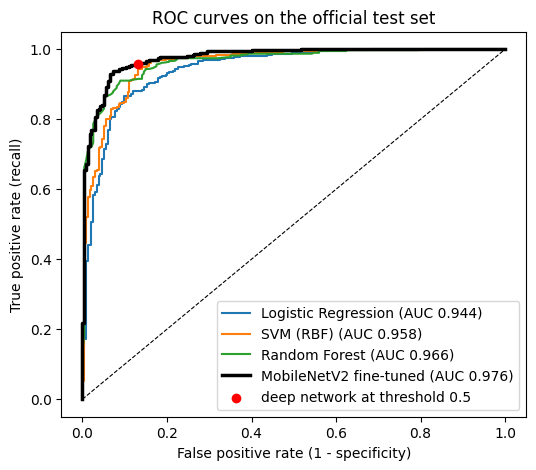

In [36]:
plt.figure(figsize=(6, 5))
for name, m in ml_models.items():
    p = m.predict_proba(Xte)[:, 1]
    f, t, _ = roc_curve(yte, p)
    plt.plot(f, t, label=f"{name} (AUC {roc_auc_score(yte, p):.3f})")

f, t, _ = roc_curve(y_test, p_test)
plt.plot(f, t, lw=2.5, c='k', label=f"MobileNetV2 fine-tuned (AUC {roc_auc_score(y_test, p_test):.3f})")
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)

# mark the deep network's operating point at threshold 0.5
pred = p_test >= 0.5
tpr_pt = (pred & (y_test == 1)).sum() / (y_test == 1).sum()
fpr_pt = (pred & (y_test == 0)).sum() / (y_test == 0).sum()
plt.scatter([fpr_pt], [tpr_pt], c='red', zorder=5, label='deep network at threshold 0.5')

plt.xlabel('False positive rate (1 - specificity)')
plt.ylabel('True positive rate (recall)')
plt.title('ROC curves on the official test set')
plt.legend(loc='lower right')
save_show('fig11_roc_all_models_test')

In [37]:
def organism(name):
    m = re.search(r'(bacteria|virus)', name)
    return m.group(1) if m else None

pn_pool = pool[pool['class'] == 'PNEUMONIA'].copy()
pn_test = test_df[test_df['class'] == 'PNEUMONIA'].copy()
for d in (pn_pool, pn_test):
    d['org'] = d.path.map(lambda p: organism(Path(p).name))

types_pool = pn_pool.groupby('patient').org.agg(set)
types_test = pn_test.groupby('patient').org.agg(set)
common = types_pool.index.intersection(types_test.index)
same_type = sum(len(types_pool[i] & types_test[i]) > 0 for i in common)

print(f"PNEUMONIA IDs in both sets: {len(common)}")
print(f"  with the same infection type in both: {same_type} ({same_type / len(common):.0%})")
print("NORMAL IDs in both sets:", len(set(pool[pool['class'] == 'NORMAL'].patient)
                                     & set(test_df[test_df['class'] == 'NORMAL'].patient)))

PNEUMONIA IDs in both sets: 170
  with the same infection type in both: 0 (0%)
NORMAL IDs in both sets: 94


In [38]:
import keras, shutil
print("tensorflow", tf.__version__, "| keras", keras.__version__)

def preprocess_bytes(b):                      # exactly what the app will do
    img = tf.io.decode_image(b, channels=3, expand_animations=False)
    img = tf.image.resize(img, (224, 224))
    return tf.expand_dims(img, 0)

m = tf.keras.models.load_model(str(CKPT_DIR / 'final_model.keras'))
for i in [0, 1, 2, 300, 500]:
    b = Path(test_df.path.iloc[i]).read_bytes()
    out = float(m.predict(preprocess_bytes(b), verbose=0)[0][0])
    print(i, test_df['class'].iloc[i], f"app: {out:.4f} | notebook: {float(p_test[i]):.4f}")

samples = CKPT_DIR / 'app_samples'; samples.mkdir(exist_ok=True)
for cls in ['NORMAL', 'PNEUMONIA']:
    for f in list_images('test', cls)[:3]:
        shutil.copy(f, samples / f"{cls}_{f.name}")
print("samples:", len(list(samples.iterdir())))

tensorflow 2.21.0 | keras 3.13.2
0 NORMAL app: 0.0485 | notebook: 0.0485
1 NORMAL app: 0.2298 | notebook: 0.2298
2 NORMAL app: 0.0563 | notebook: 0.0563
300 PNEUMONIA app: 0.9992 | notebook: 0.9992
500 PNEUMONIA app: 0.9986 | notebook: 0.9986
samples: 6


In [39]:
app_code = r'''
from pathlib import Path
import streamlit as st
import tensorflow as tf

IMG = 224
HERE = Path(__file__).parent
SAMPLES = HERE / "app_samples"

st.set_page_config(page_title="Chest X-ray Pneumonia Classifier", layout="centered")

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(HERE / "final_model.keras")

def preprocess(image_bytes):
    img = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))
    return tf.expand_dims(img, 0)

st.title("Chest X-ray Pneumonia Classifier")
st.caption("Class mini project. Fine-tuned MobileNetV2 trained on the Kaggle chest X-ray dataset. "
           "Educational demo only. Not a medical device.")

with st.sidebar:
    st.header("Settings")
    threshold = st.slider("Decision threshold", 0.05, 0.95, 0.50, 0.01,
        help="Lower: catches more pneumonia but gives more false alarms. Higher: fewer false alarms but more missed cases.")
    st.markdown("**Results on the official test set (threshold 0.5)**")
    st.markdown("- Accuracy: 92.5%\n- Recall: 95.9%\n- Specificity: 86.8%\n- ROC-AUC: 0.976")

uploaded = st.file_uploader("Upload a chest X-ray (JPEG or PNG)", type=["jpg", "jpeg", "png"])
sample_files = sorted(SAMPLES.glob("*.jp*g")) if SAMPLES.exists() else []
choice = st.selectbox("...or choose a sample image", ["(none)"] + [p.name for p in sample_files])

data, true_label = None, None
if uploaded is not None:
    data = uploaded.getvalue()
elif choice != "(none)":
    data = (SAMPLES / choice).read_bytes()
    true_label = choice.split("_")[0]

if data is not None:
    model = load_model()
    prob = float(model.predict(preprocess(data), verbose=0)[0][0])
    left, right = st.columns(2)
    left.image(data, caption="Input image")
    with right:
        st.subheader("Prediction")
        if prob >= threshold:
            st.error("Pneumonia likely")
        else:
            st.success("Normal likely")
        st.metric("Pneumonia probability", f"{prob:.1%}")
        st.progress(min(max(prob, 0.0), 1.0))
        st.caption(f"Decision threshold: {threshold:.2f}")
        if true_label:
            st.caption(f"True label of this sample: {true_label}")

with st.expander("About this model and its limitations"):
    st.markdown(
        "- Trained on one public dataset of mostly paediatric chest X-rays.\n"
        "- On the official test set about 13% of healthy images are flagged as pneumonia.\n"
        "- Image size alone predicts the class fairly well in this dataset, so the model may partly use such cues.\n"
        "- Not validated on other hospitals or adults. Never use it for real diagnosis."
    )
'''
(CKPT_DIR / 'app.py').write_text(app_code.strip() + "\n", encoding='utf-8')
(CKPT_DIR / 'requirements.txt').write_text(f"tensorflow=={tf.__version__}\nstreamlit\npillow\nnumpy\n")
print("app.py and requirements.txt written to Drive")

app.py and requirements.txt written to Drive
